# Logistic Regression

Logistic regression gives every penguin a probability of being a Chinstrap and draws **one straight line** where that probability is 0.5.

This notebook goes with the **Logistic Regression** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split into train and test → scale → fit the model → check the result → draw the decision boundary.

## 1. Load the data

Each row is a penguin. We have two measurements (**bill length** and **body mass**) and the species. The goal: predict whether a penguin is an **Adelie** or a **Chinstrap** from those two numbers.

The data is the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) data set (CC0), reduced to two species and two columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/penguins.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,species,bill_length_mm,body_mass_g
0,Adelie,39.1,3750
1,Adelie,39.5,3800
2,Adelie,40.3,3250
3,Adelie,36.7,3450
4,Adelie,39.3,3650


In [2]:
X = dataset[['bill_length_mm', 'body_mass_g']].values
y = (dataset['species'] == 'Chinstrap').astype(int).values  # 0 = Adelie, 1 = Chinstrap

print(X.shape, 'penguins, class counts:', np.bincount(y))

(219, 2) penguins, class counts: [151  68]


## 2. Split into train and test

The model learns from the **training** penguins (75%). We keep the other 25% hidden and only use them at the end, so the test score shows how the model does on penguins it has never seen. Those are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

164 train, 55 test


## 3. Scale the features

Logistic regression trains faster and more reliably when the features share a scale.

`StandardScaler` shifts each feature to an average of 0 and a spread of 1. We fit it on the **training** data only, then apply it to both sets.

In [4]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

## 4. Fit the model

This is the same code as on the lesson's Code tab (with `X_train_s` and `y_train`).

In [5]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state=0)
classifier.fit(X_train_s, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

## 5. Check the result

The **confusion matrix** counts right and wrong guesses: the diagonal is correct, everything else is a mistake. **Accuracy** is the share of test penguins the model got right.

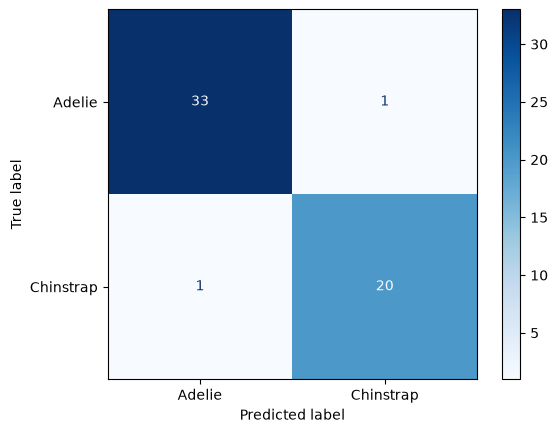

Test accuracy:  0.964
Train accuracy: 0.976


In [6]:
y_pred = classifier.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Adelie', 'Chinstrap']).plot(cmap='Blues')
plt.show()

print('Test accuracy: ', round(accuracy_score(y_test, y_pred), 3))
print('Train accuracy:', round(accuracy_score(y_train, classifier.predict(X_train_s)), 3))

## 6. Draw the decision boundary

We ask the model to classify every point on a grid and colour each cell by its answer. The boundary is a straight line. Notice how it tilts to balance the two features.

C:\jtmp\ipykernel_8796\849887601.py:10: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')


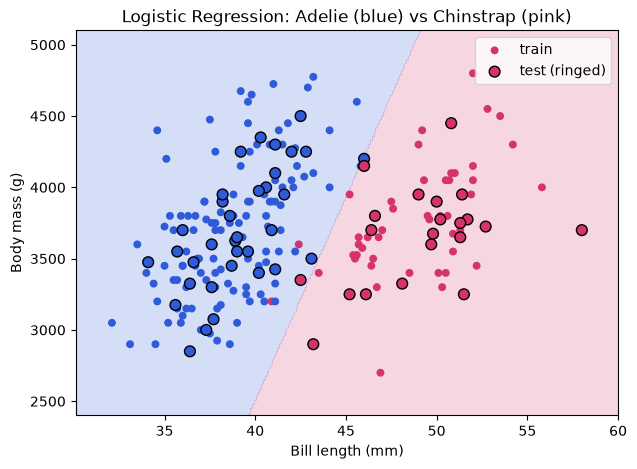

In [7]:
# a grid over the real units (mm and grams), scaled the same way as the training data
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

colors = ['#2f5bd8', '#d6336c']
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.2, levels=[-0.5, 0.5, 1.5], colors=colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=[colors[v] for v in y_train], s=22, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')
plt.xlabel('Bill length (mm)')
plt.ylabel('Body mass (g)')
plt.title('Logistic Regression: Adelie (blue) vs Chinstrap (pink)')
plt.legend()
plt.show()

## Try it yourself

- Compare `classifier.coef_` for the two features: a larger weight means the feature matters more to the score.
- Open the lesson's Compare page on the site and put Logistic Regression next to K-NN on the Moons data.

## See it: the decision boundary

Each coloured area is where the model answers "Adelie" (blue) or "Chinstrap" (raspberry). **Notice how** the boundary is one straight line. It cannot bend, so any penguin on the wrong side of that line is a mistake. The left panel shows the penguins the model learned from (filled dots). The right panel shows the penguins it has never seen (ringed dots): a ring sitting inside the wrong colour is a mistake. The accuracy is in each title.

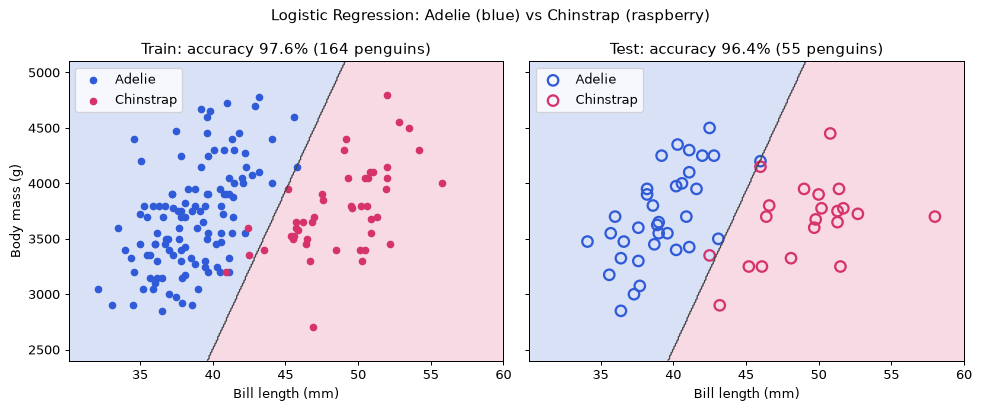

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
colors = [BLUE, PINK]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, Xp, yp, Xs in [(axes[0], 'Train', X_train, y_train, X_train_s),
                             (axes[1], 'Test', X_test, y_test, X_test_s)]:
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5], colors=colors)
    ax.contour(xx, yy, zz, levels=[0.5], colors='#444444', linewidths=1)
    acc = (classifier.predict(Xs) == yp).mean()
    for cls, label in [(0, 'Adelie'), (1, 'Chinstrap')]:
        pts = Xp[yp == cls]
        if name == 'Train':
            ax.scatter(pts[:, 0], pts[:, 1], color=colors[cls], s=26, label=label)
        else:
            ax.scatter(pts[:, 0], pts[:, 1], facecolors='none', edgecolors=colors[cls], s=70, linewidths=1.8, label=label)
    ax.set_title(f'{name}: accuracy {acc:.1%} ({len(Xp)} penguins)')
    ax.set_xlabel('Bill length (mm)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Body mass (g)')
fig.suptitle('Logistic Regression: Adelie (blue) vs Chinstrap (raspberry)')
fig.tight_layout()
plt.show()
